In [24]:
import pandas as pd

df_train = pd.read_csv("train.csv")
df_test = pd.read_csv("test.csv")

df_train.head()

,id_hex,flux_energy,resonance_str,sensor_x,sensor_y
0,2E86E,17835.148887,gardsolidverianluxhelidluxlum,-30.140797,20.628435
1,A5890,20479.820172,echofailfailkzzvoidkzzbzzfailerrnu,36.334533,-21.720997
2,49392,7801.324247,aetaetidaetluzmianaetianver,-14.463592,19.667346
3,5C0D4,11359.735179,failzecho,-9.244456,32.596626
4,E1069,26632.889062,verianobsid,-0.008725,-44.631826


In [25]:
df_train.columns

Index(['id_hex', 'flux_energy', 'resonance_str', 'sensor_x', 'sensor_y'], dtype='object')

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer
vect = TfidfVectorizer(analyzer='char', ngram_range=((2, 4)))
X_text = vect.fit_transform(df_train.resonance_str)
X_text_final = vect.transform(df_test.resonance_str)

X_text

<10000x2225 sparse matrix of type '<class 'numpy.float64'>'
	with 534799 stored elements in Compressed Sparse Row format>

In [27]:
num_features = ['flux_energy']
X_num = df_train[num_features]
X_num_final = df_test[num_features]

from scipy.sparse import hstack

X = hstack([X_num, X_text])

X

<10000x2226 sparse matrix of type '<class 'numpy.float64'>'
	with 544799 stored elements in COOrdinate format>

In [28]:
from umap import UMAP
import matplotlib.pyplot as plt
import seaborn as sns

decom = UMAP(n_components=2)
X_red = pd.DataFrame(decom.fit_transform(X_text))
X_red_final = pd.DataFrame(decom.fit_transform(X_text_final))

C:\Users\Ilie-Goga\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


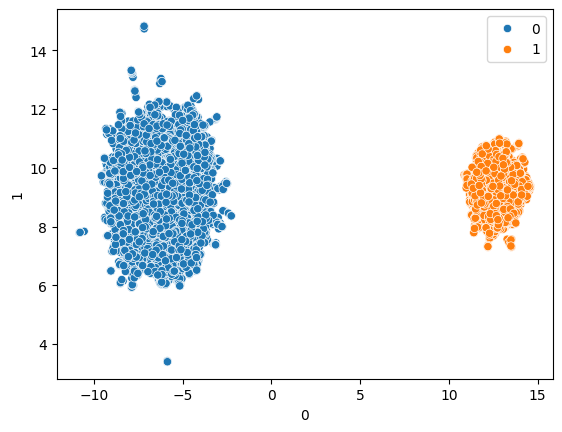

In [29]:
from sklearn.cluster import KMeans
model = KMeans(n_clusters=2)
labels = model.fit_predict(X_red)

sns.scatterplot(x=X_red[0], y=X_red[1], hue=labels)
plt.show()

In [30]:
df_test.head()

,id_hex,flux_energy,resonance_str
0,CE15,19127.183983,verluxsolluxluzmobsverlumgardl
1,F0FD5,7915.016050,ververididluxidhelidsol
2,C1984,6336.378707,luxidluxlux
3,AA7D,2406.950952,heliang
4,64091,21238.807723,kzzxxxzzrrxxxzr


In [31]:
X_final = hstack([X_num_final, X_text_final])

X_final

<3000x2226 sparse matrix of type '<class 'numpy.float64'>'
	with 162335 stored elements in COOrdinate format>

In [32]:
y_preds = model.fit_predict(X_red_final)

In [33]:
submission = pd.DataFrame({
    "subtaskID": 1,
    "datapointID": df_test.id_hex,
    "answer": y_preds
})

submission

,subtaskID,datapointID,answer
0,1,CE15,1
1,1,F0FD5,1
2,1,C1984,1
3,1,AA7D,1
4,1,64091,0
...,...,...,...
2995,1,E23C1,0
2996,1,23A8A,0
2997,1,A9650,1
2998,1,EA2D6,1


In [34]:
submission.answer.value_counts()

answer
1    2161
0     839
Name: count, dtype: int64

In [35]:
submission.to_csv("submission.csv", index=False)